<a href="https://colab.research.google.com/github/fernandyan/MyGoogleColab/blob/main/fernand_flask.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# import

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import minmax_scale

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# 1 - social midia

In [6]:
data = pd.read_csv("/content/social_media_screentime_mental_health_2026.csv")
data = data.drop('participant_id', axis=1)
data

,age,gender,occupation,region,most_used_platform,platforms_used_count,daily_screen_hours,daily_notifications,night_time_use,minutes_to_first_check_after_waking,...,life_satisfaction_1to10,loneliness_1to10,self_esteem_1to10,fomo_1to10,social_comparison_1to10,physical_activity_days_per_week,uses_screen_time_limits,attempted_digital_detox,seeks_mental_health_support,wellbeing_band
0,33,Male,Student,Latin America,TikTok,8,3.2,172,Never,25,...,9,6,4,6,8,4,No,No,No,At-risk
1,23,Female,Full-time employed,Oceania,Instagram,8,4.5,38,Often,26,...,7,5,8,5,8,4,No,"Yes, failed",Yes,At-risk
2,56,Female,Full-time employed,Africa,Instagram,1,5.3,74,Every night,12,...,8,7,3,2,3,5,No,No,No,Moderate
3,13,Male,Student,Europe,YouTube,4,3.4,49,Sometimes,21,...,10,6,6,1,5,4,No,"Yes, failed",Yes,Moderate
4,36,Female,Student,Asia,LinkedIn,5,5.8,227,Never,19,...,4,6,8,7,9,3,Yes,"Yes, succeeded",No,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,30,Male,Part-time employed,Europe,Snapchat,4,3.6,74,Never,7,...,4,4,6,3,10,2,Yes,No,No,Good
6996,28,Male,Self-employed,North America,Facebook,3,5.0,104,Every night,48,...,8,1,7,6,7,1,No,"Yes, failed",No,Moderate
6997,26,Prefer not to say,Unemployed,Oceania,LinkedIn,3,1.2,25,Never,6,...,9,4,5,1,6,3,No,No,No,Good
6998,22,Female,Student,Europe,Snapchat,4,3.6,182,Sometimes,12,...,5,7,4,1,6,2,No,"Yes, failed",No,Good


In [7]:
data.describe()

,age,platforms_used_count,daily_screen_hours,daily_notifications,minutes_to_first_check_after_waking,avg_sleep_hours,anxiety_score_0to27,low_mood_score_0to27,life_satisfaction_1to10,loneliness_1to10,self_esteem_1to10,fomo_1to10,social_comparison_1to10,physical_activity_days_per_week
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,6895.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000
mean,29.246571,3.494571,3.304971,61.528286,20.008286,6.964989,11.378000,3.845714,6.955857,4.679286,6.006857,4.641857,5.323286,2.804143
std,9.569132,1.763637,1.881350,54.879070,13.976229,0.870575,4.777726,3.534197,1.614486,2.094803,1.886767,2.157439,2.090788,1.288418
min,13.000000,1.000000,0.200000,5.000000,0.000000,3.800000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,22.000000,2.000000,1.900000,24.000000,10.000000,6.400000,8.000000,0.000000,6.000000,3.000000,5.000000,3.000000,4.000000,2.000000
50%,29.000000,3.000000,3.000000,45.500000,17.000000,7.000000,11.000000,3.000000,7.000000,5.000000,6.000000,5.000000,5.000000,3.000000
75%,36.000000,5.000000,4.300000,83.000000,27.000000,7.600000,14.000000,6.000000,8.000000,6.000000,7.000000,6.000000,7.000000,4.000000
max,71.000000,8.000000,14.000000,400.000000,111.000000,10.000000,27.000000,19.000000,10.000000,10.000000,10.000000,10.000000,10.000000,7.000000


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 24 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   age                                  7000 non-null   int64  
 1   gender                               6930 non-null   object 
 2   occupation                           7000 non-null   object 
 3   region                               7000 non-null   object 
 4   most_used_platform                   7000 non-null   object 
 5   platforms_used_count                 7000 non-null   int64  
 6   daily_screen_hours                   7000 non-null   float64
 7   daily_notifications                  7000 non-null   int64  
 8   night_time_use                       7000 non-null   object 
 9   minutes_to_first_check_after_waking  7000 non-null   int64  
 10  primary_purpose                      7000 non-null   object 
 11  avg_sleep_hours               

In [9]:
data.value_counts('most_used_platform')

,count
most_used_platform,
TikTok,1733
Instagram,1703
YouTube,1264
X/Twitter,585
Facebook,522
Snapchat,508
Reddit,411
LinkedIn,274


In [10]:
data.value_counts('age')

,count
age,
13,439
29,316
30,306
31,288
26,267
32,256
28,255
27,251
25,250


In [11]:
data.value_counts('region')

,count
region,
Asia,1959
North America,1842
Europe,1834
Latin America,670
Africa,425
Oceania,270


In [12]:
data.value_counts('social_comparison_1to10')

,count
social_comparison_1to10,
6,1232
5,1214
4,1074
7,969
3,798
8,625
2,378
9,287
1,249


In [13]:
data['most_used_platform'].unique(), data['gender'].unique(), data['region'].unique(), data['region'].unique(), data['night_time_use'].unique(), data['social_comparison_1to10'].unique()

(array(['TikTok', 'Instagram', 'YouTube', 'LinkedIn', 'X/Twitter',
        'Facebook', 'Snapchat', 'Reddit'], dtype=object),
 array(['Male', 'Female', 'Prefer not to say', 'Non-binary', nan],
       dtype=object),
 array(['Latin America', 'Oceania', 'Africa', 'Europe', 'Asia',
        'North America'], dtype=object),
 array(['Latin America', 'Oceania', 'Africa', 'Europe', 'Asia',
        'North America'], dtype=object),
 array(['Never', 'Often', 'Every night', 'Sometimes'], dtype=object),
 array([ 8,  3,  5,  9,  7, 10,  4,  6,  1,  2]))

In [14]:
data.isna().sum()

,0
age,0
gender,70
occupation,0
region,0
most_used_platform,0
platforms_used_count,0
daily_screen_hours,0
daily_notifications,0
night_time_use,0
minutes_to_first_check_after_waking,0


In [15]:
data.value_counts('most_used_platform')

,count
most_used_platform,
TikTok,1733
Instagram,1703
YouTube,1264
X/Twitter,585
Facebook,522
Snapchat,508
Reddit,411
LinkedIn,274


{'whiskers': [<matplotlib.lines.Line2D at 0x7fab15801ac0>,
 'caps': [<matplotlib.lines.Line2D at 0x7fab15801430>,
 'boxes': [<matplotlib.lines.Line2D at 0x7fab15cadcd0>],
 'medians': [<matplotlib.lines.Line2D at 0x7fab15800e90>],
 'fliers': [<matplotlib.lines.Line2D at 0x7fab15800800>],
 'means': []}

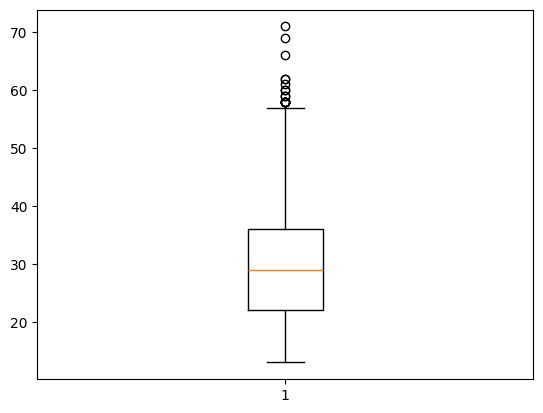

In [16]:
plt.boxplot(data['age'])

(array([ 191.,  569., 1198., 1095., 1718., 1263.,  448.,  359.,  121.,
          38.]),
 array([ 0. ,  2.7,  5.4,  8.1, 10.8, 13.5, 16.2, 18.9, 21.6, 24.3, 27. ]),
 <BarContainer object of 10 artists>)

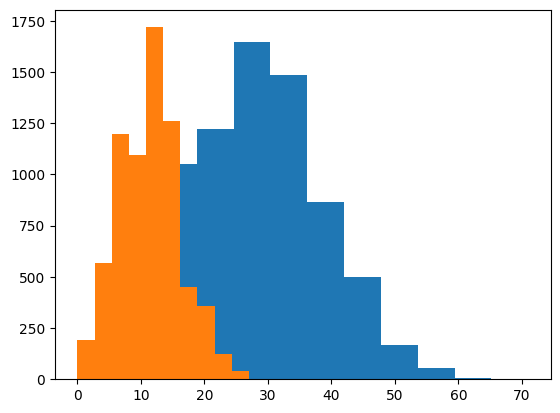

In [17]:
plt.hist(data['age'])
plt.hist(data['anxiety_score_0to27'])

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(), ['gender', 'occupation', 'region', 'most_used_platform', 'night_time_use', 'uses_screen_time_limits', 'attempted_digital_detox', 'seeks_mental_health_support', 'primary_purpose']),
        # ('cat', OrdinalEncoder(), ['gender', 'occupation', 'region', 'most_used_platform', 'night_time_use', 'uses_screen_time_limits', 'attempted_digital_detox', 'seeks_mental_health_support', 'wellbeing_band', 'primary_purpose']),
    ],
    remainder='passthrough' # Options: 'drop' or 'passthrough'
)

In [19]:
data_pre = preprocessor.fit_transform(data)

In [20]:
input = SimpleImputer(strategy='most_frequent')

In [21]:
data_pre = input.fit_transform(data_pre)

In [22]:
preprocessor.get_feature_names_out()

array(['cat__gender', 'cat__occupation', 'cat__region',
       'cat__most_used_platform', 'cat__night_time_use',
       'cat__uses_screen_time_limits', 'cat__attempted_digital_detox',
       'cat__seeks_mental_health_support', 'cat__primary_purpose',
       'remainder__age', 'remainder__platforms_used_count',
       'remainder__daily_screen_hours', 'remainder__daily_notifications',
       'remainder__minutes_to_first_check_after_waking',
       'remainder__avg_sleep_hours', 'remainder__anxiety_score_0to27',
       'remainder__low_mood_score_0to27',
       'remainder__life_satisfaction_1to10',
       'remainder__loneliness_1to10', 'remainder__self_esteem_1to10',
       'remainder__fomo_1to10', 'remainder__social_comparison_1to10',
       'remainder__physical_activity_days_per_week',
       'remainder__wellbeing_band'], dtype=object)

In [23]:
data_pre = pd.DataFrame(data_pre, columns=preprocessor.get_feature_names_out())
data_pre

,cat__gender,cat__occupation,cat__region,cat__most_used_platform,cat__night_time_use,cat__uses_screen_time_limits,cat__attempted_digital_detox,cat__seeks_mental_health_support,cat__primary_purpose,remainder__age,...,remainder__avg_sleep_hours,remainder__anxiety_score_0to27,remainder__low_mood_score_0to27,remainder__life_satisfaction_1to10,remainder__loneliness_1to10,remainder__self_esteem_1to10,remainder__fomo_1to10,remainder__social_comparison_1to10,remainder__physical_activity_days_per_week,remainder__wellbeing_band
0,1.0,4.0,3.0,5.0,1.0,0.0,0.0,1.0,2.0,33,...,8.7,17,0,9,6,4,6,8,4,At-risk
1,0.0,0.0,5.0,1.0,2.0,0.0,1.0,2.0,2.0,23,...,7.3,18,2,7,5,8,5,8,4,At-risk
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,56,...,7.0,12,6,8,7,3,2,3,5,Moderate
3,1.0,4.0,2.0,7.0,3.0,0.0,1.0,2.0,3.0,13,...,7.0,13,0,10,6,6,1,5,4,Moderate
4,0.0,4.0,1.0,2.0,1.0,1.0,2.0,1.0,5.0,36,...,6.7,15,1,4,6,8,7,9,3,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,1.0,1.0,2.0,4.0,1.0,1.0,0.0,1.0,2.0,30,...,5.9,2,8,4,4,6,3,10,2,Good
6996,1.0,3.0,4.0,0.0,0.0,0.0,1.0,1.0,4.0,28,...,5.8,13,0,8,1,7,6,7,1,Moderate
6997,3.0,5.0,5.0,2.0,1.0,0.0,0.0,1.0,0.0,26,...,8.6,8,9,9,4,5,1,6,3,Good
6998,0.0,4.0,2.0,4.0,3.0,0.0,1.0,1.0,4.0,22,...,7.3,9,4,5,7,4,1,6,2,Good


In [24]:
X = data_pre.drop('remainder__wellbeing_band', axis=1)
y = data_pre['remainder__wellbeing_band']

In [25]:
data_pre = minmax_scale(X)

In [26]:
preprocessor.get_feature_names_out()

array(['cat__gender', 'cat__occupation', 'cat__region',
       'cat__most_used_platform', 'cat__night_time_use',
       'cat__uses_screen_time_limits', 'cat__attempted_digital_detox',
       'cat__seeks_mental_health_support', 'cat__primary_purpose',
       'remainder__age', 'remainder__platforms_used_count',
       'remainder__daily_screen_hours', 'remainder__daily_notifications',
       'remainder__minutes_to_first_check_after_waking',
       'remainder__avg_sleep_hours', 'remainder__anxiety_score_0to27',
       'remainder__low_mood_score_0to27',
       'remainder__life_satisfaction_1to10',
       'remainder__loneliness_1to10', 'remainder__self_esteem_1to10',
       'remainder__fomo_1to10', 'remainder__social_comparison_1to10',
       'remainder__physical_activity_days_per_week',
       'remainder__wellbeing_band'], dtype=object)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## select model

In [28]:
svm = SVC()
gau = GaussianNB()
knn = KNeighborsClassifier()
dtc = DecisionTreeClassifier()
rfc = RandomForestClassifier()
gbc = GradientBoostingClassifier()
abc = AdaBoostClassifier()
mlp = MLPClassifier()

In [29]:
# for i in [svm, gau, knn, dtc, rfc, gbc, abc, mlp]:
#   i.fit(X_train, y_train)
#   print(f"{i} - {i.score(X_test, y_test)}")

In [30]:
# cross = cross_val_score(rfc, X, y, cv=4)
# cross

In [31]:
param_grid_knn = [{
    "n_neighbors":[1,3,5,7],
    "weights":["uniform", "distance"],
    "leaf_size":[10,20,50]
    # "algorithm":["auto", "ball_tree", "kd_tree", "brute"]
}]

In [32]:
# grid_seach = GridSearchCV(knn, param_grid_knn, cv=4, return_train_score=True, verbose=10, scoring="accuracy")
# grid_seach.fit(X, y)

In [33]:
# final_knn = grid_seach.best_estimator_
# final_knn

In [34]:
# final_knn.score(X_test, y_test)

In [35]:
param_grid_svm = [{
    "C":[60,100],
    "kernel":["poly", "rbf", "sigmoid"],
    # "degree":[1,3,5],
    # "gamma":["auto", "scale"]
}]

In [36]:
# grid_seach = GridSearchCV(svm, param_grid_svm, cv=4, return_train_score=True, verbose=10, scoring="accuracy")
# grid_seach.fit(X, y)

In [37]:
# final_svm = grid_seach.best_estimator_
# final_svm

In [38]:
# final_svm.score(X_test, y_test)

In [39]:
param_grid_gau = [{
    # "priors":[1, 10,20,30,50,100,200],
    "var_smoothing":[1e-09, 1e-10, 1e-11, 1, 10]
}]

In [40]:
# grid_seach = GridSearchCV(gau, param_grid_gau, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [41]:
# final_gau = grid_seach.best_estimator_
# final_gau

In [42]:
# final_gau.score(X_test, y_test)

In [43]:
param_grid_dtc = [{
    "criterion":["gini","entropy","log_loss"],
    "splitter":["best", "random"],
    "max_depth":[10,20,30],
}]

In [44]:
# grid_seach = GridSearchCV(dtc, param_grid_dtc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [45]:
# final_dtc = grid_seach.best_estimator_
# final_dtc

In [46]:
# final_dtc.score(X_test, y_test)

In [47]:
param_grid_rfc = [{
    "n_estimators":[1,500],
    "criterion":["gini","entropy","log_loss"],
    "max_depth":[10,50],
}]

In [48]:
# grid_seach = GridSearchCV(rfc, param_grid_rfc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [49]:
# final_rfc = grid_seach.best_estimator_
# final_rfc

In [50]:
# final_rfc.score(X_test, y_test)

In [51]:
param_grid_gbc = [{
    "n_estimators":[10,50],
    # "loss":["log_loss","exponential"],
    "learning_rate":[0.5, 0.1],
}]

In [52]:
# grid_seach = GridSearchCV(gbc, param_grid_gbc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [53]:
# final_gbc = grid_seach.best_estimator_
# final_gbc

In [54]:
# final_gbc.score(X_test, y_test)

In [55]:
param_grid_abc = [{
    "n_estimators":[5, 10],
    # "loss":["log_loss","exponential"],
    "learning_rate":[0.5, 0.1],
}]

In [56]:
# grid_seach = GridSearchCV(abc, param_grid_abc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [57]:
# final_abc = grid_seach.best_estimator_
# final_abc

In [58]:
# final_abc.score(X_test, y_test)

In [78]:
param_grid_mlp = [{
    "hidden_layer_sizes":[5, 10, 50],
    "activation":["identity","logistic", "tanh","relu"],
    # "solver":["lbfgs","sgd", "adam"],
    "learning_rate_init":[0.01, 0.5],
}]

In [79]:
grid_seach = GridSearchCV(mlp, param_grid_mlp, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
grid_seach.fit(X, y)

Fitting 4 folds for each of 24 candidates, totalling 96 fits
[CV 1/4; 1/24] START activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01
[CV 1/4; 1/24] END activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.905, test=0.905) total time=   3.3s
[CV 2/4; 1/24] START activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01
[CV 2/4; 1/24] END activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.921, test=0.914) total time=   2.4s
[CV 3/4; 1/24] START activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01
[CV 3/4; 1/24] END activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.897, test=0.893) total time=   0.9s
[CV 4/4; 1/24] START activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01
[CV 4/4; 1/24] END activation=identity, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.869, test=0.883) total time=   1.0s
[CV 1/4; 2/24] START activation

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV 2/4; 7/24] END activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.970, test=0.967) total time=   1.8s
[CV 3/4; 7/24] START activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.01
[CV 3/4; 7/24] END activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.930, test=0.931) total time=   1.3s
[CV 4/4; 7/24] START activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.01
[CV 4/4; 7/24] END activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.01;, score=(train=0.947, test=0.947) total time=   1.6s
[CV 1/4; 8/24] START activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.5
[CV 1/4; 8/24] END activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.5;, score=(train=0.538, test=0.538) total time=   0.2s
[CV 2/4; 8/24] START activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.5
[CV 2/4; 8/24] END activation=logistic, hidden_layer_sizes=5, learning_rate_init=0.5;, score=(t

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV 2/4; 21/24] END activation=relu, hidden_layer_sizes=10, learning_rate_init=0.01;, score=(train=0.987, test=0.983) total time=   1.9s
[CV 3/4; 21/24] START activation=relu, hidden_layer_sizes=10, learning_rate_init=0.01
[CV 3/4; 21/24] END activation=relu, hidden_layer_sizes=10, learning_rate_init=0.01;, score=(train=0.887, test=0.877) total time=   0.8s
[CV 4/4; 21/24] START activation=relu, hidden_layer_sizes=10, learning_rate_init=0.01
[CV 4/4; 21/24] END activation=relu, hidden_layer_sizes=10, learning_rate_init=0.01;, score=(train=0.966, test=0.963) total time=   1.8s
[CV 1/4; 22/24] START activation=relu, hidden_layer_sizes=10, learning_rate_init=0.5
[CV 1/4; 22/24] END activation=relu, hidden_layer_sizes=10, learning_rate_init=0.5;, score=(train=0.538, test=0.538) total time=   0.2s
[CV 2/4; 22/24] START activation=relu, hidden_layer_sizes=10, learning_rate_init=0.5
[CV 2/4; 22/24] END activation=relu, hidden_layer_sizes=10, learning_rate_init=0.5;, score=(train=0.538, test=0

GridSearchCV(cv=4, error_score='raise', estimator=MLPClassifier(),
             param_grid=[{'activation': ['identity', 'logistic', 'tanh',
                                         'relu'],
                          'hidden_layer_sizes': [5, 10, 50],
                          'learning_rate_init': [0.01, 0.5]}],
             return_train_score=True, scoring='accuracy', verbose=10)

In [80]:
final_mlp = grid_seach.best_estimator_
final_mlp

MLPClassifier(hidden_layer_sizes=10, learning_rate_init=0.01)

In [81]:
final_mlp.score(X_test, y_test)

0.9664285714285714